# Hamiltonian flow and symplectic integrators

**Source:** CompSci §4.4.2, pp. 30–36 · [Source map](../docs/SOURCES.md) · [Course index](../README.md)

In canonical order $(q,p)$, Hamilton's equations are $\dot q=H_p$, $\dot p=-H_q$. The cross terms cancel in $dH/dt$. A stably stratified particle near equilibrium reduces to $\ddot q=-\omega^2 q$; in scaled units $H=(p^2+q^2)/2$. Exact flow preserves phase area and energy. A map with Jacobian $M$ is symplectic if $M^\top JM=J$, $J=\begin{pmatrix}0&1\\-1&0\end{pmatrix}$. This implies volume preservation, which alone is not sufficient in higher dimensions.

For separable $H=T(p)+V(q)$, the drift and kick are exact split flows. Composing a kick and drift gives symplectic Euler; half kick, full drift, half kick gives second-order Störmer–Verlet. Implicit midpoint is symplectic; for this quadratic Hamiltonian it also conserves exact energy. Symplecticity in general gives good long-time energy behaviour under suitable hypotheses, not exact conservation of $H$.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.22,
                     "axes.spines.top": False, "axes.spines.right": False})
root = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "01_Foundations").is_dir() and (p / "requirements.txt").is_file())
out = root / "assets" / "figures"
out.mkdir(parents=True, exist_ok=True)

def show(fig, name):
    fig.tight_layout()
    fig.savefig(out / (name + ".png"), dpi=150, bbox_inches="tight")
    plt.show()
    plt.close(fig)

Matplotlib is building the font cache; this may take a moment.


Forward Euler area factor 1.0144
Backward Euler area factor 0.985804
Symplectic Euler area factor 1.0
Verlet area factor 1.0
Implicit midpoint area factor 1.0


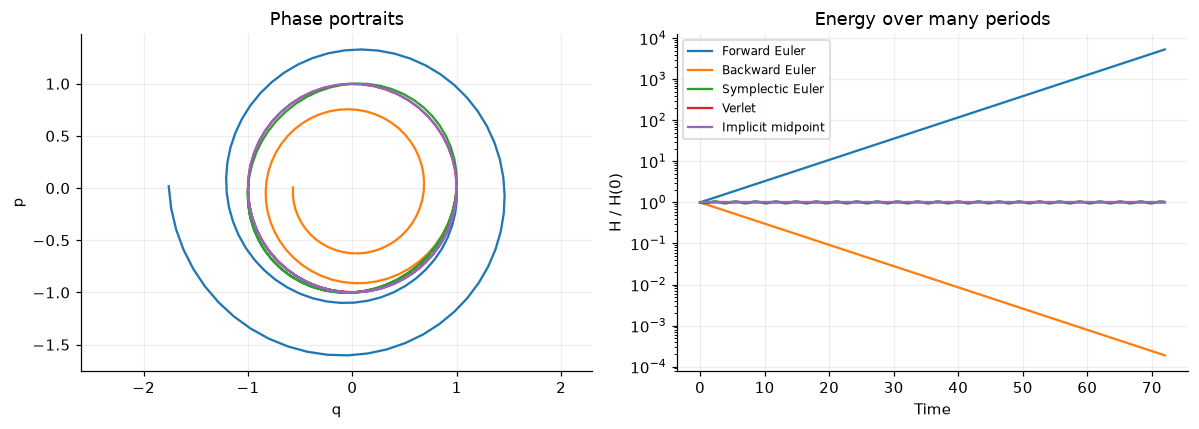

In [2]:
h=.12; I=np.eye(2); J=np.array([[0.,1.],[-1.,0.]])
def kick(h): return np.array([[1,0],[-h,1]])
def drift(h): return np.array([[1,h],[0,1]])
maps={"Forward Euler":I+h*J,"Backward Euler":np.linalg.solve(I-h*J,I),
      "Symplectic Euler":drift(h)@kick(h),
      "Verlet":kick(h/2)@drift(h)@kick(h/2),
      "Implicit midpoint":np.linalg.solve(I-h*J/2,I+h*J/2)}
fig,ax=plt.subplots(1,2,figsize=(11,4))
for name,M in maps.items():
    y=np.empty((601,2)); y[0]=[1,0]
    for i in range(len(y)-1): y[i+1]=M@y[i]
    energy=np.sum(y*y,axis=1)
    ax[0].plot(*y[:80].T,label=name)
    ax[1].semilogy(h*np.arange(len(y)),energy,label=name)
    if name in ["Symplectic Euler","Verlet","Implicit midpoint"]:
        assert np.allclose(M.T@J@M,J)
        assert np.max(abs(energy-1))<.15
    print(name, "area factor", round(np.linalg.det(M),6))
ax[0].set(xlabel="q",ylabel="p",title="Phase portraits"); ax[0].axis("equal")
ax[1].set(xlabel="Time",ylabel="H / H(0)",title="Energy over many periods"); ax[1].legend(fontsize=8)
show(fig,"04-hamiltonian")

## Worked exercise

**Why does forward Euler spiral outward?** Its area factor is $1+h^2>1$ and its energy is multiplied by the same factor each step. Backward Euler shrinks area. Stability on negative real eigenvalues does not make it a good conservative integrator.

## Further practice

Replace the force -q with -sin(q) for Verlet. Use H=p²/2+1-cos(q), and compare two initial angles.

Record: prediction → observation → explanation. A successful assertion checks this example; it is not a general proof.